# Proyecto 3: Mejorando algoritmos con CUDA

CC3069 Computación Paralela y Distribuida, Sección 20. Roberto Barreda, Nina Najera y José Antón.

Este notebook recorre la solución del Laboratorio 3 de Data Science (reconocimiento de señas ASL) y su versión acelerada. El flujo está separado en dos fases. La fase 1 prepara las imágenes en el CPU, con uno o con varios procesos. La fase 2 entrena la red neuronal, primero en el CPU como referencia secuencial y después en la GPU con CUDA.

El código está en la carpeta src. Este notebook solo llama a esas funciones y muestra sus resultados. El análisis completo está en docs/informe/informe.pdf.

In [1]:
import os
import sys
import time
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

# El NPZ pesa unos 200 MB. Conviene guardarlo fuera de carpetas sincronizadas como OneDrive.
NPZ = Path(os.environ.get("ASL_NPZ", RAIZ / "results" / "asl_prepared.npz"))
print("Proyecto:", RAIZ)
print("Archivo de datos preparados:", NPZ)

Proyecto: C:\Users\rjbar\OneDrive\Documents\GitHub\Computacion_Paralela
Archivo de datos preparados: C:\Users\rjbar\datasets\p3_work\asl_prepared.npz


## 1. Entorno de ejecución

Se comprueba qué hardware reconoce cada biblioteca. TensorFlow, que usa el Laboratorio 3, solo ve el CPU porque desde la versión 2.11 no usa la GPU en Windows nativo. PyTorch sí reconoce la GPU, y por eso el modelo se tradujo a PyTorch.

In [2]:
import json

import tensorflow as tf
import torch

from src.benchmark import info_sistema
from src.gpu_training import verify_cuda

print(json.dumps(info_sistema(), indent=2, ensure_ascii=False))
print("Dispositivos que ve TensorFlow:", [d.device_type for d in tf.config.list_physical_devices()])
print(json.dumps(verify_cuda(), indent=2, ensure_ascii=False))

{
  "sistema": "Windows-11-10.0.26200-SP0",
  "python": "3.12.10",
  "cpu": "13th Gen Intel(R) Core(TM) i9-13900HX",
  "nucleos_fisicos": 24,
  "nucleos_logicos": 32,
  "ram_gb": 15.7,
  "torch": "2.13.0+cu130",
  "hilos_torch": 24,
  "cuda_disponible": true,
  "gpu": "NVIDIA GeForce RTX 4080 Laptop GPU",
  "vram_mb": 12282,
  "sms": 58,
  "compute_capability": "8.9",
  "cuda_torch": "13.0",
  "cudnn": 92000,
  "driver_nvidia": "616.92"
}


Dispositivos que ve TensorFlow: ['CPU']


{
  "torch": "2.13.0+cu130",
  "cuda_disponible": true,
  "cuda_torch": "13.0",
  "cudnn": 92000,
  "gpu": "NVIDIA GeForce RTX 4080 Laptop GPU",
  "compute_capability": "8.9",
  "sms": 58,
  "memoria_total_mb": 12282,
  "modelo_forward_backward_ok": true
}


## 2. Fase 1: preparación de imágenes en el CPU

La selección de imágenes usa la función original del Laboratorio 3 (src/preprocess_images.py): 600 imágenes por clase con semilla 42, divididas en 70 %, 15 % y 15 %. Después, prepare_arrays de src/cpu_pipeline.py abre cada JPEG, lo convierte a RGB, lo redimensiona a 64 por 64 con LANCZOS y divide los píxeles entre 255.

Con workers igual a 1 las imágenes se procesan una por una. Con más procesos, las rutas se reparten en lotes de 200 entre procesos independientes. Se usan procesos y no hilos porque el intérprete de Python solo ejecuta código de Python en un hilo a la vez. Esta fase no usa la GPU.

In [3]:
from src.benchmark import huella
from src.cpu_pipeline import IMAGE_SIZE, SEED, prepare_arrays, start_pool
from src.preprocess_images import create_split_manifest

inicio = time.perf_counter()
manifest = create_split_manifest(images_per_class=600, seed=SEED)
print(f"Selección del split: {time.perf_counter() - inicio:.2f} s, {len(manifest)} imágenes")
display(manifest.groupby("split").size().rename("imágenes").to_frame())

inicio = time.perf_counter()
secuencial = prepare_arrays(manifest, IMAGE_SIZE, "float32", workers=1)
t_secuencial = time.perf_counter() - inicio
print(f"Preparación con 1 proceso: {t_secuencial:.2f} s")

inicio = time.perf_counter()
pool = start_pool(8)
arranque = time.perf_counter() - inicio
try:
    inicio = time.perf_counter()
    paralelo = prepare_arrays(manifest, IMAGE_SIZE, "float32", workers=8, pool=pool)
    t_paralelo = time.perf_counter() - inicio
finally:
    pool.shutdown(wait=True)
print(f"Preparación con 8 procesos: {t_paralelo:.2f} s más {arranque:.2f} s de arranque del pool")
print(f"Speedup del trabajo: {t_secuencial / t_paralelo:.2f}x")
print("Mismos datos en ambas versiones:", huella(secuencial) == huella(paralelo))

Selección del split: 12.60 s, 17400 imágenes


,imágenes
split,
test,2610
train,12180
validation,2610


Preparación con 1 proceso: 12.71 s


Preparación con 8 procesos: 2.63 s más 1.83 s de arranque del pool
Speedup del trabajo: 4.84x


Mismos datos en ambas versiones: True


In [4]:
import numpy as np

NPZ.parent.mkdir(parents=True, exist_ok=True)
inicio = time.perf_counter()
np.savez_compressed(NPZ, **paralelo)
print(f"NPZ guardado en {time.perf_counter() - inicio:.2f} s")
print({k: v.shape for k, v in paralelo.items() if k.startswith("X_")})
del secuencial, paralelo

NPZ guardado en 29.39 s
{'X_train': (12180, 3, 64, 64), 'X_val': (2610, 3, 64, 64), 'X_test': (2610, 3, 64, 64)}


## 3. Solución secuencial original del Laboratorio 3

El código original se midió sin cambios con src/keras_referencia.py. La primera parte ejecuta el ajuste del laboratorio para la familia de CNN mejorada, que lee los JPEG con tf.data. La configuración elegida fue cnn_improved_a. La segunda parte entrena esa configuración durante diez épocas con los mismos arreglos preparados en la fase 1. Volver a ejecutarlo toma varios minutos, así que aquí se muestran los resultados guardados.

Para repetirlo: python -m src.keras_referencia original y python -m src.keras_referencia validacion --config cnn_improved_a --npz RUTA.

In [5]:
ajuste = pd.read_csv(RAIZ / "results" / "keras_referencia" / "ajuste_cnn_improved.csv")
display(ajuste[["model_name", "training_time_seconds", "epochs_completed", "validation_accuracy"]])
keras = pd.read_csv(RAIZ / "results" / "keras_referencia" / "validacion_keras_cpu.csv")
display(keras[["corrida", "train_s", "epoch_mean_s", "test_acc", "parametros"]])

,model_name,training_time_seconds,epochs_completed,validation_accuracy
0,cnn_improved_a,55.57,3,0.782759
1,cnn_improved_b,87.11,3,0.324521


,corrida,train_s,epoch_mean_s,test_acc,parametros
0,1,181.497649,18.130227,0.98046,165509
1,2,202.823345,20.262687,0.98046,165509


## 4. Fase 2: entrenamiento del modelo

src/gpu_training.py contiene la red cnn_improved_a traducida a PyTorch capa por capa, con los mismos valores por defecto de Keras. La misma función train_once entrena en el CPU y en la GPU, así que las dos versiones ejecutan el mismo código con los mismos datos, épocas, tamaño de lote y semilla. Esta fase no lee imágenes, solo carga el NPZ de la fase 1.

In [6]:
from src.gpu_training import HP, cargar_datos, crear_modelo, train_once

modelo = crear_modelo(HP)
print(modelo)
print("Parámetros entrenables:", sum(p.numel() for p in modelo.parameters()))
print("Configuración:", HP)
datos = cargar_datos(str(NPZ))

CNNMejorada(
  (conv): Sequential(
    (0): Conv2d(3, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(24, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(24, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(24, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (8): BatchNorm2d(48, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (11): BatchNorm2d(48, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilatio

### 4.1 Referencia secuencial en el CPU

Un entrenamiento completo de diez épocas en el CPU tarda cerca de tres minutos.

In [7]:
cpu = train_once(datos, HP, torch.device("cpu"), "directo", False)
print(f"CPU: entrenamiento {cpu['train_s']:.2f} s, prueba {cpu['test_s']:.3f} s, exactitud {cpu['test_acc']:.4f}")

    ép 01/10 train_loss=2.5802 val_loss=4.9909 val_acc=0.0345  (20.40s)


    ép 02/10 train_loss=1.3850 val_loss=4.4951 val_acc=0.0345  (20.91s)


    ép 03/10 train_loss=0.7869 val_loss=1.0872 val_acc=0.7322  (20.82s)


    ép 04/10 train_loss=0.5022 val_loss=0.5799 val_acc=0.8406  (20.60s)


    ép 05/10 train_loss=0.3504 val_loss=0.3894 val_acc=0.8843  (20.68s)


    ép 06/10 train_loss=0.2448 val_loss=0.4922 val_acc=0.8636  (20.74s)


    ép 07/10 train_loss=0.1899 val_loss=0.3979 val_acc=0.8966  (20.76s)


    ép 08/10 train_loss=0.1431 val_loss=0.3168 val_acc=0.9019  (20.81s)


    ép 09/10 train_loss=0.1189 val_loss=0.1258 val_acc=0.9728  (20.90s)


    ép 10/10 train_loss=0.0936 val_loss=0.1679 val_acc=0.9425  (20.89s)


CPU: entrenamiento 207.52 s, prueba 1.347 s, exactitud 0.9444


### 4.2 Entrenamiento con CUDA

En el modo optimizado el conjunto completo se copia una vez a la memoria de la GPU y los lotes se toman de ahí. cudnn.benchmark deja que cuDNN elija el algoritmo de convolución más rápido para cada capa. Antes de medir se hace una época corta de calentamiento. La última variante reemplaza la capa densa final por kernels propios escritos con Numba (src/numba_dense.py).

In [8]:
from src.numba_dense import crear_modelo_numba

gpu = torch.device("cuda")
torch.backends.cudnn.benchmark = True
pequeno = {k: v[:512] for k, v in datos.items()}
resultados = {"CPU": cpu}
for nombre, fabrica in (("GPU optimizado", None), ("GPU con kernel Numba", crear_modelo_numba)):
    train_once(pequeno, {**HP, "epochs": 1}, gpu, "optimizado", False, modelo=fabrica)
    resultados[nombre] = train_once(datos, HP, gpu, "optimizado", False, modelo=fabrica)

tabla = pd.DataFrame({
    nombre: {"entrenamiento_s": r["train_s"], "prueba_s": r["test_s"], "memoria_gpu_mb": r["peak_mem_mb"],
             "exactitud_prueba": r["test_acc"], "speedup_entrenamiento": cpu["train_s"] / r["train_s"]}
    for nombre, r in resultados.items()
}).T
display(tabla.round(3))

    ép 01/1 train_loss=3.5024 val_loss=3.6489 val_acc=0.1758  (1.27s)


    ép 01/10 train_loss=2.5280 val_loss=7.7668 val_acc=0.0345  (1.34s)


    ép 02/10 train_loss=1.3590 val_loss=6.1262 val_acc=0.0345  (1.02s)


    ép 03/10 train_loss=0.7668 val_loss=1.3863 val_acc=0.5805  (1.03s)


    ép 04/10 train_loss=0.4829 val_loss=1.0600 val_acc=0.6521  (1.02s)


    ép 05/10 train_loss=0.3402 val_loss=0.5275 val_acc=0.8670  (1.00s)


... (13 outputs left out)

    ép 08/10 train_loss=0.1426 val_loss=0.2586 val_acc=0.9341  (1.00s)


    ép 09/10 train_loss=0.1120 val_loss=0.2672 val_acc=0.9080  (1.00s)


    ép 10/10 train_loss=0.0982 val_loss=0.2118 val_acc=0.9471  (1.00s)


,entrenamiento_s,prueba_s,memoria_gpu_mb,exactitud_prueba,speedup_entrenamiento
CPU,207.519,1.347,0.000,0.944,1.000
GPU optimizado,10.426,0.078,1219.664,0.979,19.904
GPU con kernel Numba,10.116,0.078,1219.664,0.939,20.514


## 5. Kernels CUDA

Los kernels propios de Numba se comparan con PyTorch sobre datos aleatorios. La tabla muestra la configuración de grid y bloque de cada lanzamiento para un lote de 64 imágenes. Después se muestran los tipos de kernel que lanza un paso de entrenamiento, registrados con torch.profiler en src/gpu_profile.py.

In [9]:
from src.numba_dense import verificar

verificacion = verificar()
print("Diferencia máxima contra PyTorch:", verificacion["diferencia_maxima"])
display(pd.DataFrame([{"lanzamiento": k, "grid": g, "bloque": b} for k, (g, b) in verificacion["lanzamientos"].items()]))
display(pd.read_csv(RAIZ / "results" / "perfil_gpu" / "categorias_estandar.csv").round(2))

Diferencia máxima contra PyTorch: {'salida': 1.33514404296875e-05, 'grad_x': 5.7220458984375e-06, 'grad_peso': 1.1444091796875e-05, 'grad_sesgo': 2.86102294921875e-06}


,lanzamiento,grid,bloque
0,forward matmul_tiles,"(2, 4)","(16, 16)"
1,forward sumar_sesgo,"(2, 4)","(16, 16)"
2,backward matmul_tiles grad_x,"(6, 4)","(16, 16)"
3,backward matmul_tiles grad_peso,"(6, 2)","(16, 16)"
4,backward sumar_columnas grad_sesgo,"(29,)","(256,)"


,categoria,total_us,lanzamientos,porcentaje_tiempo,lanzamientos_por_paso
0,Convolución,44447.41,460,48.58,23.0
1,Normalización por lotes,21660.35,240,23.67,12.0
2,Operaciones elemento a elemento,12226.31,500,13.36,25.0
3,Pooling,5724.71,120,6.26,6.0
4,Cambio de formato NCHW y NHWC,5314.01,520,5.81,26.0
5,Optimizador Adam,1466.04,140,1.60,7.0
6,Reducciones,310.08,100,0.34,5.0
7,Multiplicación de matrices,194.78,60,0.21,3.0
8,Pérdida y softmax,119.11,80,0.13,4.0
9,Otros,30.30,20,0.03,1.0


## 6. Resultados del benchmark

src/benchmark.py ejecutó cinco corridas por variante con un monitor de recursos, y src/benchmark_report.py calculó las tablas y las figuras. Estos son los resultados guardados en results/benchmark.

,objetivo,Preparación,Guardado y carga,Entrenamiento,Prueba,Total
0,cpu,26.76,34.58,176.00,1.38,238.71
1,gpu_directo,26.76,34.58,12.83,0.10,74.26
2,gpu_optimizado,26.76,34.58,11.61,0.08,73.02
3,gpu_numba,26.76,34.58,14.60,0.08,76.01
4,gpu_optimizado_paralelo,17.57,34.58,11.61,0.08,63.83


,fase,objetivo,speedup
12,Entrenamiento,gpu_directo,13.72
13,Prueba,gpu_directo,14.44
14,Pipeline completo,gpu_directo,3.21
15,Pipeline según Amdahl,gpu_directo,3.21
16,Entrenamiento,gpu_numba,12.14
17,Prueba,gpu_numba,17.73
18,Pipeline completo,gpu_numba,3.14
19,Pipeline según Amdahl,gpu_numba,3.14
20,Entrenamiento,gpu_optimizado,15.27
21,Prueba,gpu_optimizado,17.53


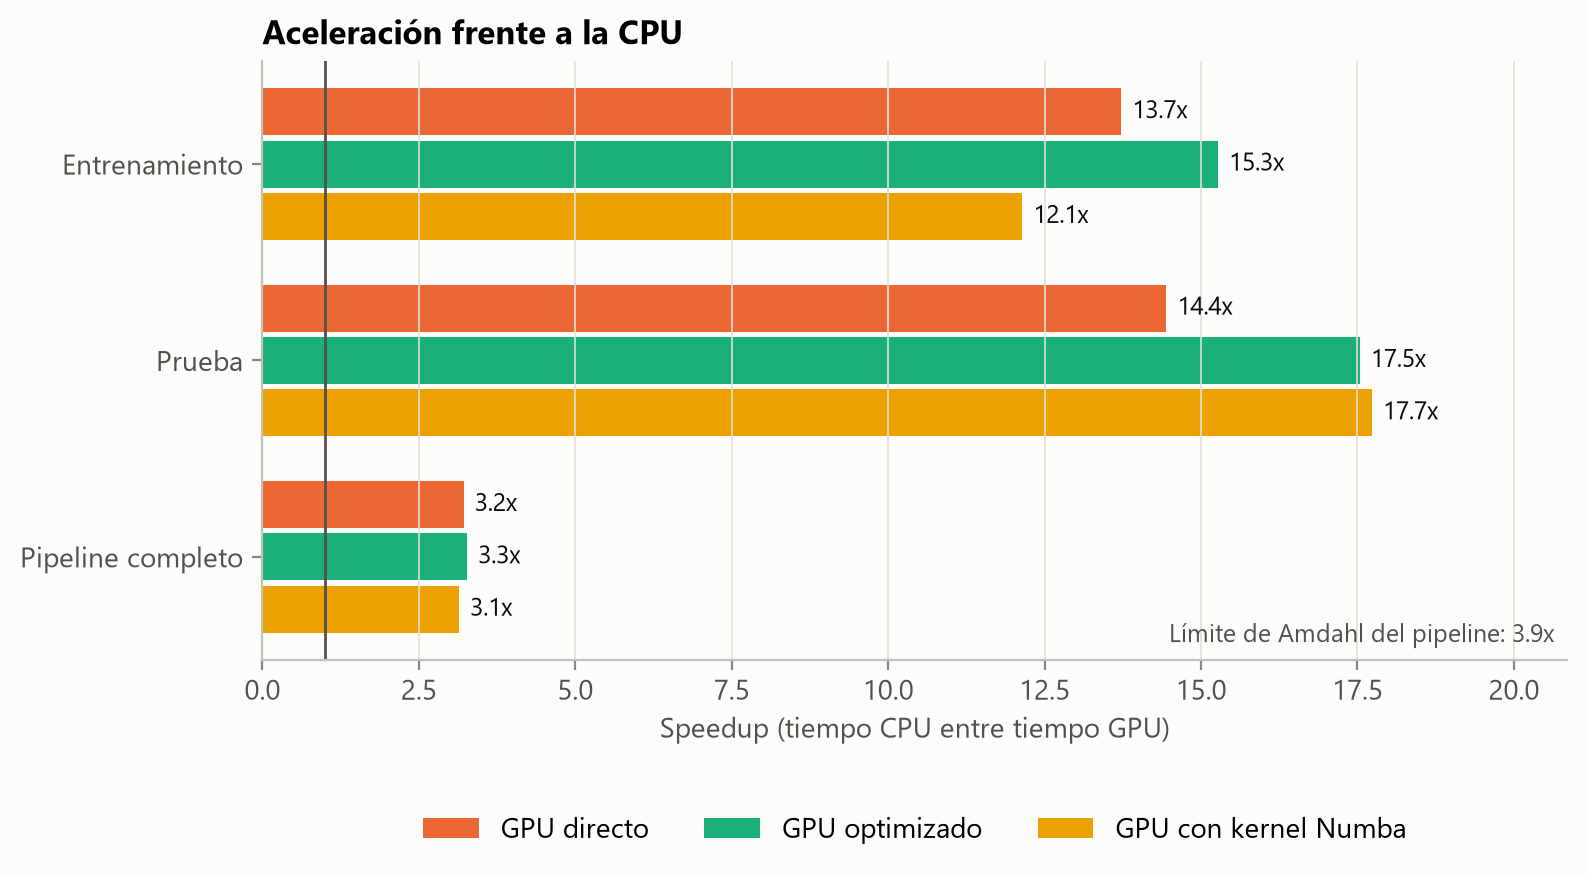

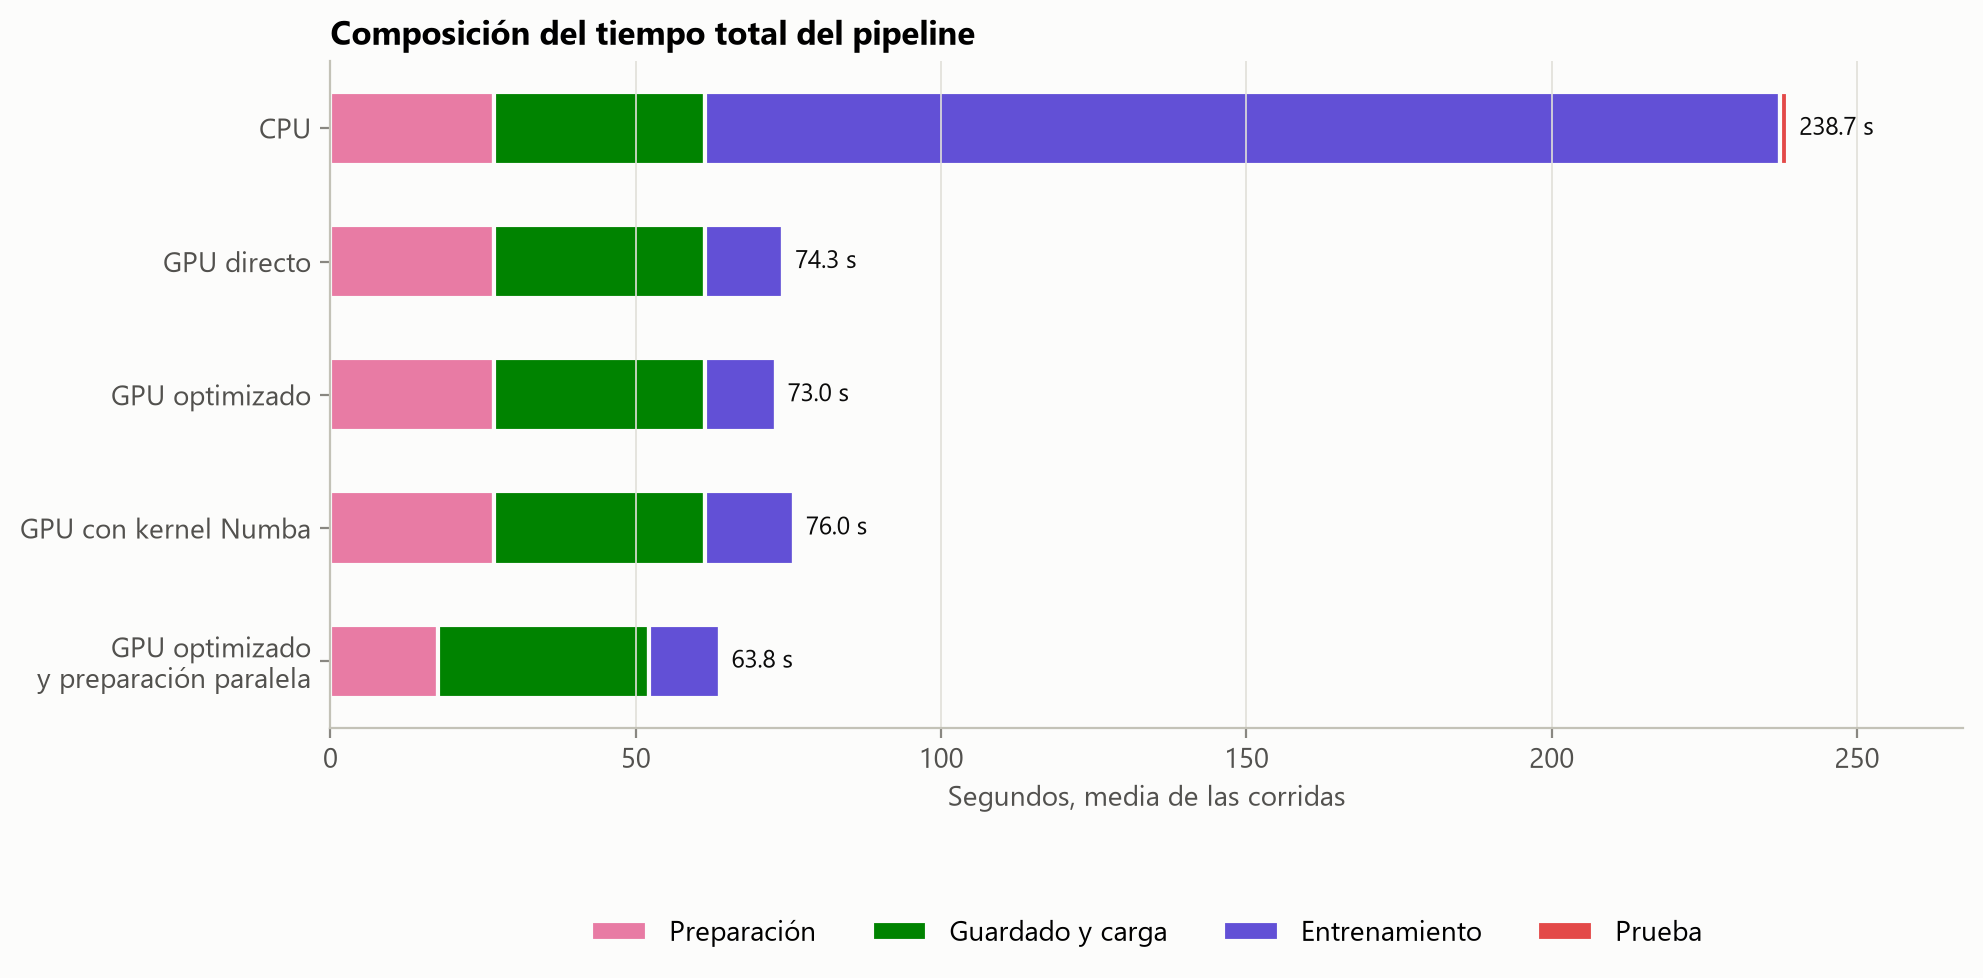

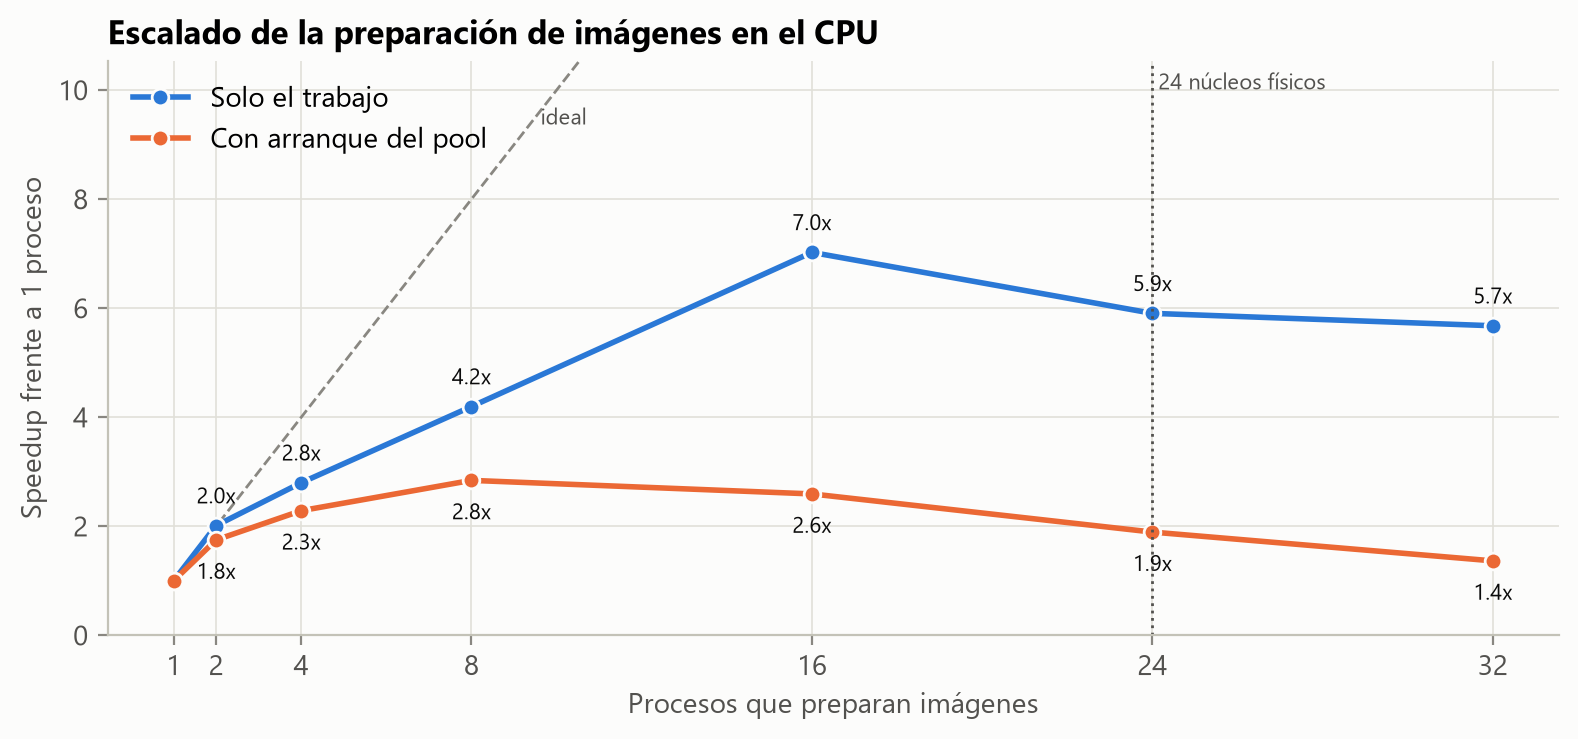

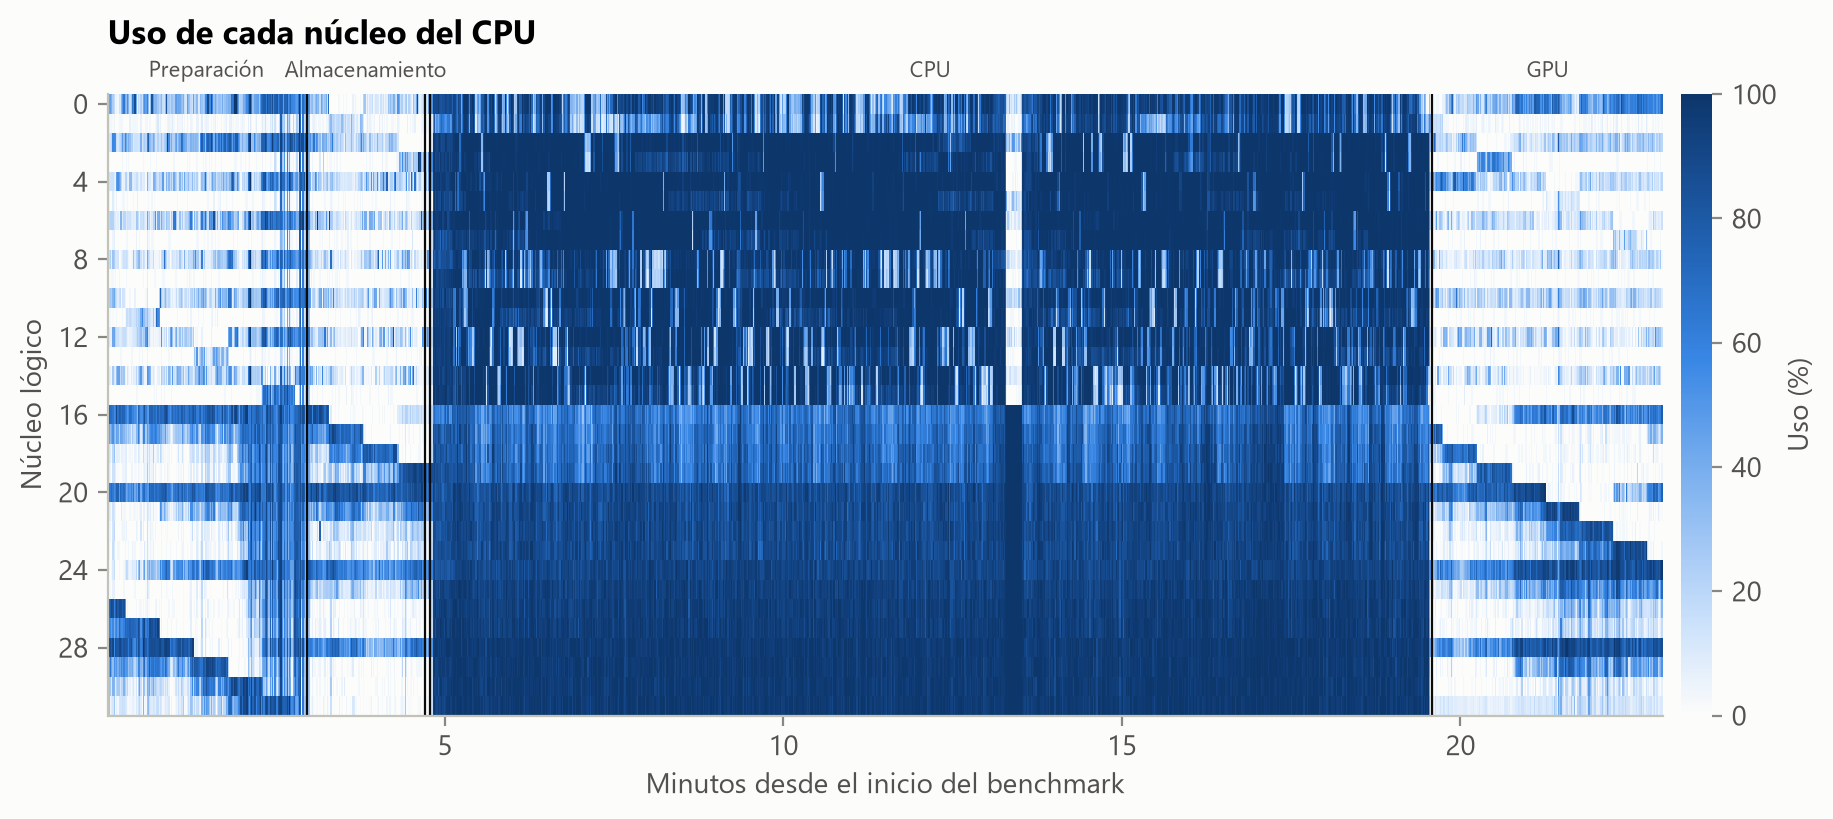

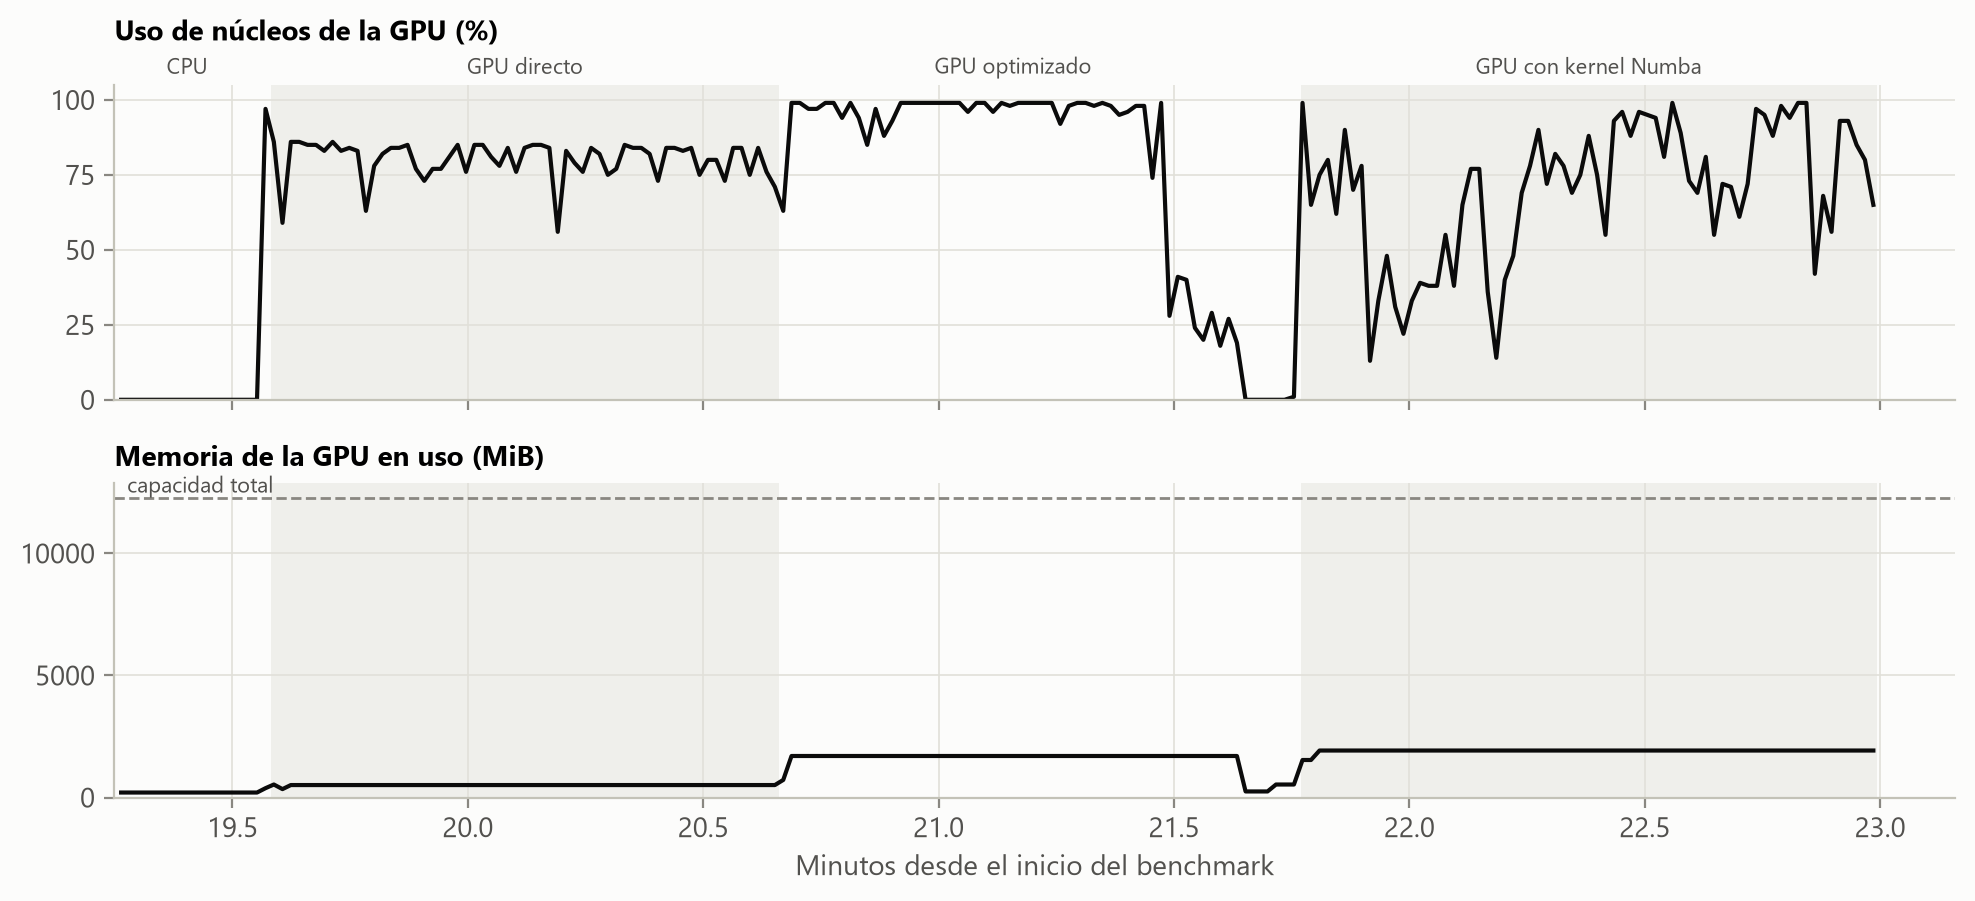

In [10]:
bench = RAIZ / "results" / "benchmark"
display(pd.read_csv(bench / "tabla_pipeline.csv").round(2))
speedup = pd.read_csv(bench / "tabla_speedup.csv")
display(speedup[~speedup["fase"].str.startswith("Preparación")].round(2))
for figura in ("speedup.png", "pipeline_composicion.png", "escalado_preparacion.png", "uso_cpu_nucleos.png", "uso_gpu_detalle.png"):
    display(Image(filename=str(bench / "figuras" / figura), width=850))

## 7. Cómo reproducir

Descargar el dataset con python -m src.download_dataset. Ejecutar el benchmark completo con python -m src.benchmark --npz RUTA y generar tablas y figuras con python -m src.benchmark_report. El perfil de kernels se obtiene con python -m src.gpu_profile --npz RUTA. Las tablas del informe se regeneran con python docs/informe/generar_tablas.py.